# Лабораторная работа №2. Pandas и корреляционный анализ

В работе используются данные `titanic.csv` и `brainsize.txt` из задания.
Основные вычисления вынесены в `pandas_tasks.py` и `correlation_tasks.py`.
Здесь приведены результаты, графики и выводы.

Ноутбук нужно запускать из папки репозитория, выполняя ячейки по порядку.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pandas_tasks import analyze_titanic
from correlation_tasks import analyze_brain_correlations
from grader_contracts.pandas_tasks import TitanicInput
from grader_contracts.correlation_tasks import BrainDataInput

sns.set_theme(style="whitegrid")
plots_dir = Path("plots")
plots_dir.mkdir(exist_ok=True)

## 1. Анализ Titanic

Сначала загружаем таблицу и считаем пропуски во всех столбцах.
Условие «старше 30 лет» означает строго `Age > 30`. Строки без возраста
не входят в этот подсчёт.

In [2]:
titanic = analyze_titanic(TitanicInput("titanic.csv"))
print("Всего пассажиров:", titanic.row_count)
print("Пассажиров старше 30 лет:", titanic.adults_over_30_count)
pd.Series(titanic.missing_by_column, name="Пропуски").to_frame()

Всего пассажиров: 891
Пассажиров старше 30 лет: 305


,Пропуски
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Для среднего возраста используем `groupby("Pclass")["Age"].mean()`:
пропущенные значения не участвуют в среднем и не заменяются нулями.
Доля выживших равна среднему столбца `Survived`, поскольку в нём 1 означает
выживание, а 0 — гибель.

In [3]:
class_statistics = pd.DataFrame({
    "Средний возраст": titanic.mean_age_by_pclass,
    "Доля выживших": titanic.survival_rate_by_pclass,
})
class_statistics.index.name = "Pclass"
class_statistics.round(4)

,Средний возраст,Доля выживших
Pclass,,
1,38.2334,0.6296
2,29.8776,0.4728
3,25.1406,0.2424


In [4]:
pd.Series(titanic.highest_fares, name="Fare").to_frame()

,Fare
0,512.3292
1,512.3292
2,512.3292
3,263.0000
4,263.0000


В таблице 891 пассажир, из них 305 старше 30 лет. Возраст отсутствует
у 177 пассажиров. Средний возраст составляет примерно 38,23 года в первом
классе, 29,88 во втором и 25,14 в третьем.

Доля выживших в этих данных равна примерно 62,96%, 47,28% и 24,24%
соответственно. Пять самых высоких тарифов: 512,3292; 512,3292; 512,3292;
263,0; 263,0. Повторяющиеся тарифы сохранены: условие не требует выбирать
только уникальные значения.

## 2. Корреляции с MRI_Count

Файл имеет табличный разделитель `\t`, а `NA` обозначает пропуск.
Разделяем наблюдения по `Gender`. Для каждой пары признаков коэффициент
Пирсона рассчитывается по строкам, в которых известны оба значения.
Например, пропуск в `Weight` не исключает строку из расчёта связи `FSIQ`
с `MRI_Count`.

In [5]:
brain = pd.read_csv("brainsize.txt", sep="\t", na_values="NA")
brain_summary = analyze_brain_correlations(BrainDataInput("brainsize.txt"))
features = ["FSIQ", "VIQ", "PIQ", "Weight", "Height"]
print("Мужчин:", brain_summary.men_count)
print("Женщин:", brain_summary.women_count)
brain.isna().sum().to_frame("Пропуски")

Мужчин: 20
Женщин: 20


,Пропуски
Gender,0
FSIQ,0
VIQ,0
PIQ,0
Weight,2
Height,1
MRI_Count,0


In [6]:
correlations = pd.DataFrame({
    "Мужчины": brain_summary.men_mri_correlation,
    "Женщины": brain_summary.women_mri_correlation,
})
print("Признак с наибольшим модулем корреляции:", brain_summary.strongest_mri_feature)
correlations.round(4)

Признак с наибольшим модулем корреляции: PIQ


,Мужчины,Женщины
FSIQ,0.4984,0.3257
VIQ,0.4131,0.2549
PIQ,0.5682,0.3962
Weight,-0.0769,0.4463
Height,0.3015,0.1745


### Диаграммы рассеяния

Каждая точка соответствует одному наблюдению. По горизонтали отложен
исследуемый признак, по вертикали — `MRI_Count`. Группы показаны отдельно.

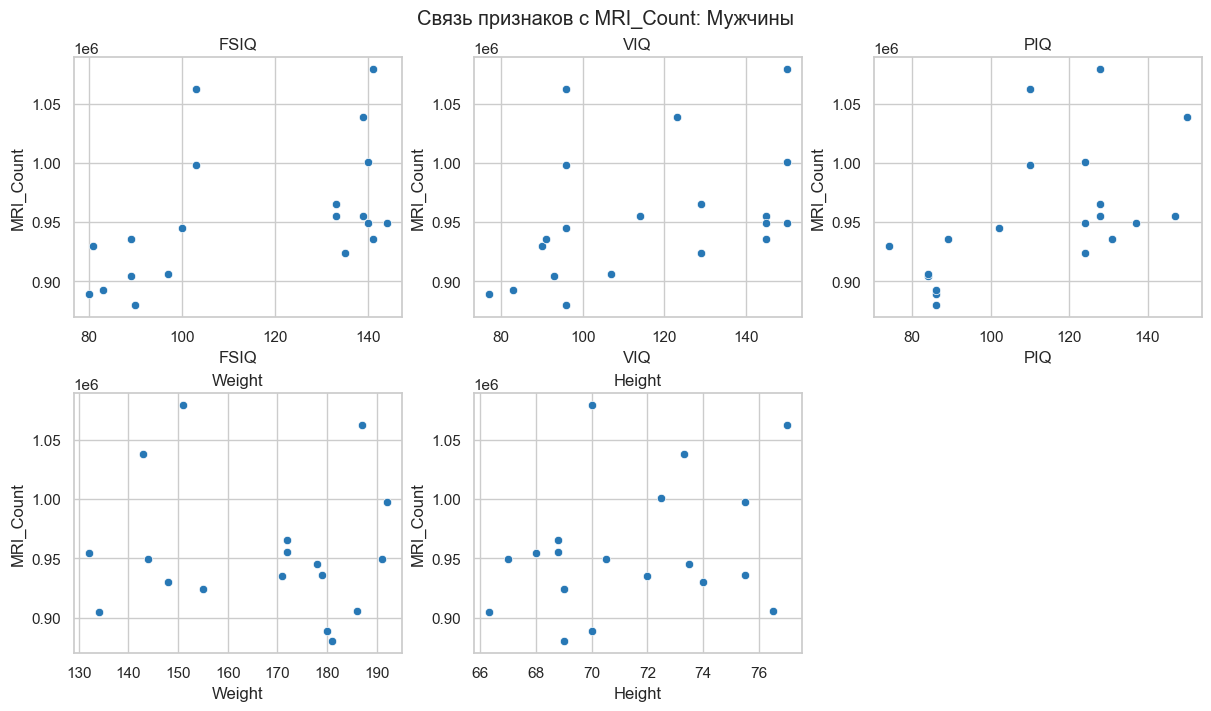

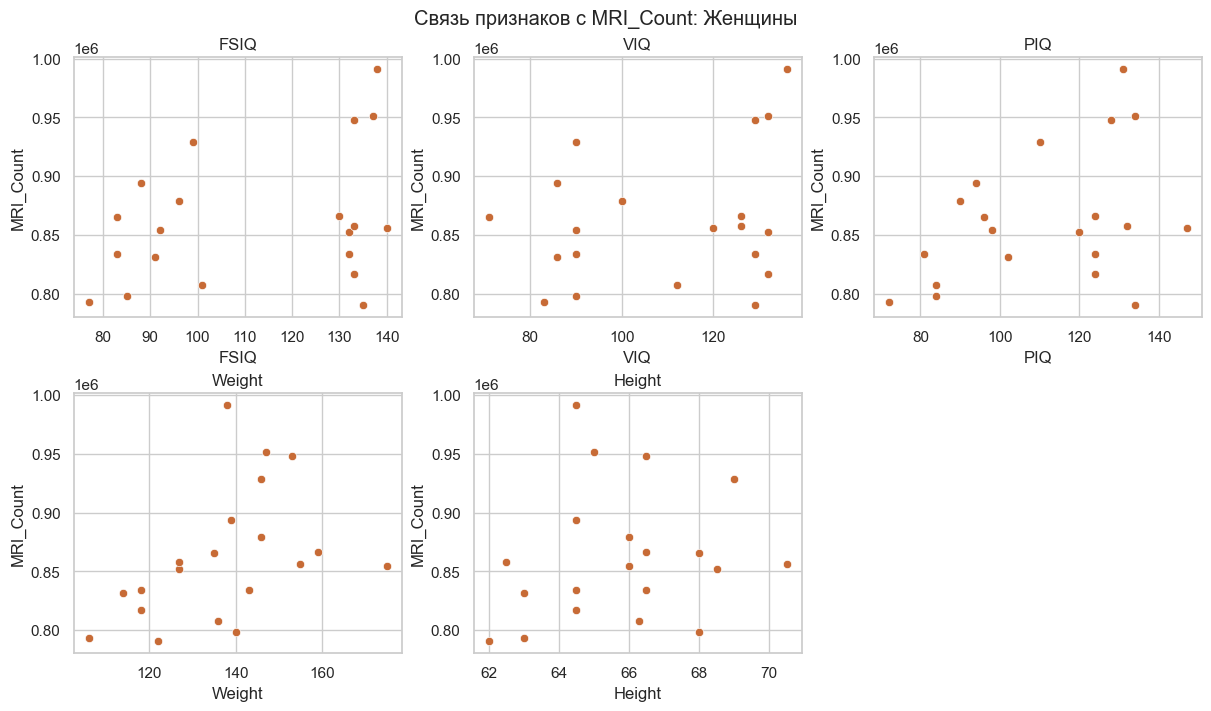

In [7]:
for gender, title, color in [("Male", "Мужчины", "#2878b5"),
                             ("Female", "Женщины", "#c76b36")]:
    group = brain[brain["Gender"] == gender]
    figure, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
    for feature, axis in zip(features, axes.flat):
        sns.scatterplot(data=group, x=feature, y="MRI_Count", ax=axis, color=color)
        axis.set_title(feature)
    axes.flat[-1].set_visible(False)
    figure.suptitle(f"Связь признаков с MRI_Count: {title}")
    figure.savefig(plots_dir / f"scatter_{gender.lower()}.png", dpi=130, bbox_inches="tight")
    plt.show()

### Тепловые карты корреляций

Шкала одинакова для обеих групп: от −1 до 1. Для выбора самого сильного
признака сравниваются модули коэффициентов из столбца `MRI_Count` обеих
групп. Корреляция `MRI_Count` с самим собой в этот выбор не входит.

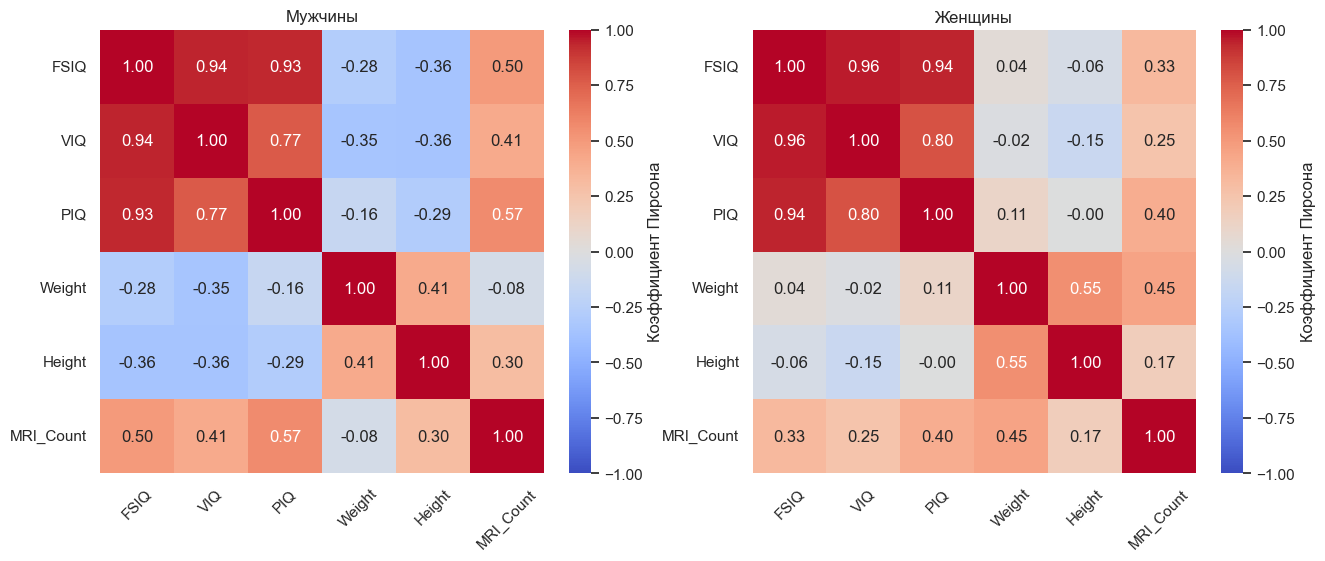

In [8]:
columns = features + ["MRI_Count"]
figure, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
for gender, title, axis in zip(["Male", "Female"], ["Мужчины", "Женщины"], axes):
    matrix = brain.loc[brain["Gender"] == gender, columns].corr(method="pearson")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, square=True, ax=axis,
                cbar_kws={"label": "Коэффициент Пирсона"})
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=45)
    axis.tick_params(axis="y", rotation=0)
figure.savefig(plots_dir / "correlation_heatmaps.png", dpi=130, bbox_inches="tight")
plt.show()

### Выводы

В каждой группе по 20 наблюдений. Наибольший модуль корреляции с
`MRI_Count` среди двух групп получен у `PIQ` для мужчин: **r ≈ 0,5682**.
Поэтому функция возвращает `strongest_mri_feature = "PIQ"`.
У женщин самый большой модуль коэффициента получен у `Weight`:
**r ≈ 0,4463**. Корреляция `Weight` с `MRI_Count` у мужчин близка к нулю:
**r ≈ −0,0769**.

Коэффициент Пирсона описывает линейную связь. Положительное значение
означает, что большие значения одного признака обычно сочетаются с большими
значениями другого. Это не доказывает причинную связь. Выборки небольшие,
поэтому полученные значения следует рассматривать как описание этих данных,
а не как общий вывод обо всех людях.

## Проверка решения

В `test_lab2.py` находятся тесты на небольших таблицах с заранее известными
результатами. Они проверяют пропуски, границу возраста 30 лет, повторяющиеся
тарифы, разделение по полу и выбор сильной отрицательной корреляции по модулю.

Из папки репозитория: `python -m unittest -v test_lab2.py`.